##**Лабораторная  работа №1**
**Цель**: Освоение навыков решения задачи регрессии с использованием модели линейной регрессии. Подбор гиперпараметров на примере степенного параметра полиномиальной регрессии.

**Задачи работы**

1. **Загрузить и изучить датасет** `Auto MPG`:
   - Ознакомиться с признаками и целевой переменной.
   - Провести предварительный анализ: распределения, корреляции, визуализации.

2. **Подготовить данные**:
   - Удалить пропущенные значения.
   - Разделить данные на обучающую и тестовую выборки.
   - Применить стандартизацию признаков.

3. **Обучить и оценить обычную линейную регрессию**:
   - Построить модель линейной регрессии.
   - Оценить качество с помощью метрик `MSE` и `R²`.
   - Визуализировать результаты.

4. **Реализовать полиномиальную регрессию**:
   - Изучить возможности `PolynomialFeatures` и `cross_val_score`.
   - Собрать `Pipeline`, включающий трансформеры и модель.
   - Применить кросс-валидацию для оценки качества моделей с разными степенями.

5. **Подобрать оптимальную степень полинома**:
   - Сравнить средние значения `R²` по фолдам для разных степеней.
   - Выбрать степень, обеспечивающую наилучший баланс между сложностью и качеством.

6. **Обучить финальную модель**:
   - Обучить модель с выбранной степенью на обучающей выборке.
   - Оценить её качество на тестовой выборке.
   - Сравнить с результатами линейной регрессии и сделать выводы.

**<font color="red">Обратите внимание</font> - каждый пункт содержит вопросы (в конце), на которые нужно ответить письменно**

In [ ]:
!pip install scikit-learn

In [2]:
# Ячейка для подключения библиотек - просто запустите ее

# Импорт библиотек для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Импорт библиотек для работы с данными
import pandas as pd
import numpy as np

# Импорт инструментов для разделения данных и предобработки
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Импорт модели линейной регрессии и метрик оценки
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Импорт инструментов для создания полиномиальных признаков и построения пайплайнов
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

Matplotlib is building the font cache; this may take a moment.


## **1. Загрузка датасета**





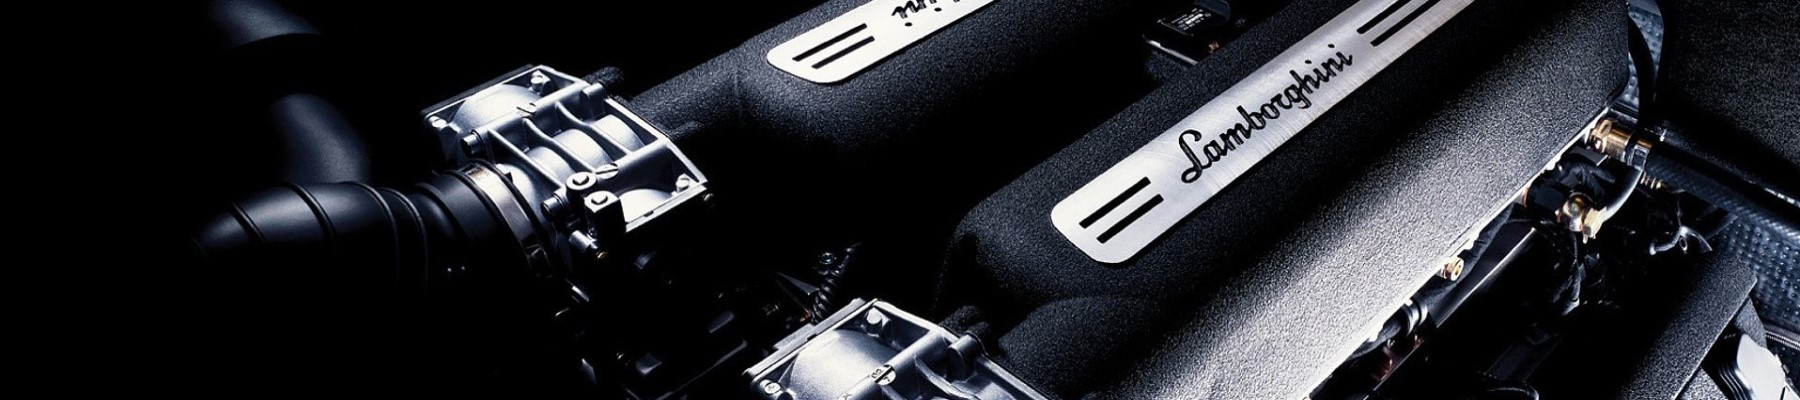

**Название:** Auto MPG  
**Источник:** [UCI Machine Learning Repository](http://archive.ics.uci.edu/ml/datasets/Auto+MPG)  
**Описание:**  
Датасет содержит информацию о характеристиках автомобилей и их расходе топлива. Он часто используется для задач регрессии, где целевой переменной является **расход топлива в милях на галлон (mpg)**.

**Целевая переменная:**
- `mpg` — расход топлива (миль на галлон), непрерывная числовая величина.

**Признаки:**
- `cylinders` — количество цилиндров (целое число).
- `displacement` — объём двигателя (литры), непрерывная величина.
- `horsepower` — мощность двигателя (лошадиные силы), непрерывная величина (содержит пропущенные значения, обозначенные символом `?`).
- `weight` — вес автомобиля (фунты), непрерывная величина.
- `acceleration` — ускорение (секунды до 60 миль/ч), непрерывная величина.
- `model_year` — год выпуска (целое число, от 70 до 82).
- `origin` — страна происхождения (1: США, 2: Европа, 3: Япония), категориальный признак.
- `car_name` — название модели автомобиля (обычно не используется в модели).

**Пропущенные значения:** Присутствуют в столбце `horsepower` (обозначены `?`).

**Примечание:**  
Для задач машинного обучения столбец `car_name` обычно исключается, а признак `origin` может быть закодирован, если используется в модели.

**Задание:**  
Загрузите датасет `Auto MPG` с официального репозитория UCI по следующему URL:  
`http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data`.  
Используйте `pandas.read_csv`, указав:
- `names` — список названий столбцов.
- `sep=r'\s+'` — разделитель — один или несколько пробелов.
- `na_values='?'` — обозначение пропущенных значений.  
Выведите первые 5 строк (`df.head()`) и информацию о типах данных (`df.info()`).

**Ответьте на вопросы:**
- Сколько всего строк и столбцов в датасете?
- Какие типы данных представлены в каждом столбце?
- Какие признаки являются числовыми, а какие — категориальными или строковыми?

##### **Ответы на вопросы:**
1) 398 строк и 9 столбцов
2) Типы столбцов
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str

4) числовые: mpg, cylinders, displacement, horsepower, weight, acceleration, model_year, origin; строковые: car_name


In [19]:
column_names = [
    'mpg', 'cylinders', 'displacement', 'horsepower','weight',
    'acceleration','model_year','origin','car_name'
]
df=pd.read_csv(
    'auto-mpg.data.txt',
    names=column_names,
    sep=r'\s+',
    na_values='?'
)
df.head()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


## **2. Предварительный анализ данных**

**Задание:**  
- Удалите строки с пропущенными значениями с помощью `.dropna()`.
- Оставьте только числовые столбцы с помощью `df.select_dtypes(include=['number'])`.
- Разделите признаки `X` (все столбцы, кроме `mpg`) и целевую переменную `y` (`mpg`).
- Постройте гистограммы для всех признаков: `X.hist(bins=20, figsize=(12, 10))`, проанализируйте их распределения.
- Рассчитайте корреляцию каждого признака с `y`: `X.corrwith(y)`, отсортируйте по убыванию.
- Постройте **тепловую карту корреляции** между всеми числовыми признаками с помощью `seaborn.heatmap`.
- Постройте графики `mpg` от 3 признаков с наибольшей корреляцией (используйте `matplotlib.pyplot` и `scatter`, по одной оси - значение признака, по другой - целевое значение).

In [5]:
df=df.dropna()
df=df.select_dtypes(include=['number'])
df.shape

(392, 8)

In [7]:
X=df.drop(columns='mpg')
y=df['mpg']
y.head()

0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64

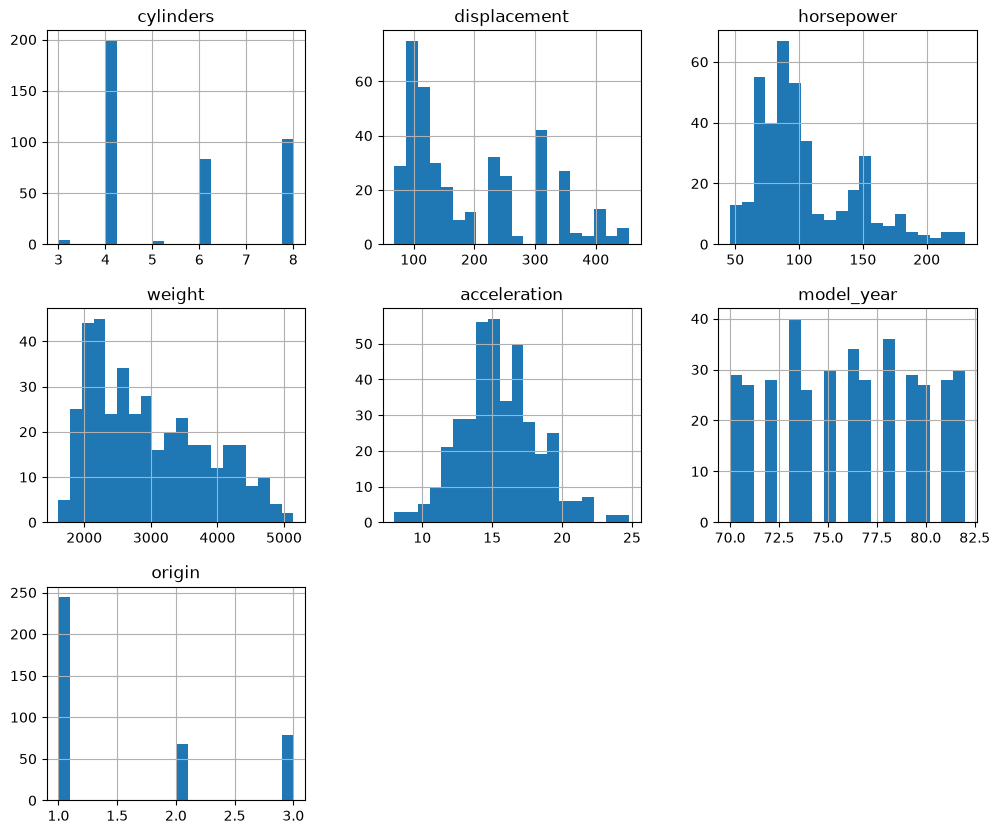

In [8]:
X.hist(bins=20,figsize=(12,10))
plt.show()

In [ ]:
corr=X.corrwith(y).sort_values(ascending=False)
corr.head(10)

model_year      0.580541
origin          0.565209
acceleration    0.423329
cylinders      -0.777618
horsepower     -0.778427
dtype: float64

In [10]:
print(corr.abs().sort_values(ascending=False))

weight          0.832244
displacement    0.805127
horsepower      0.778427
cylinders       0.777618
model_year      0.580541
origin          0.565209
acceleration    0.423329
dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

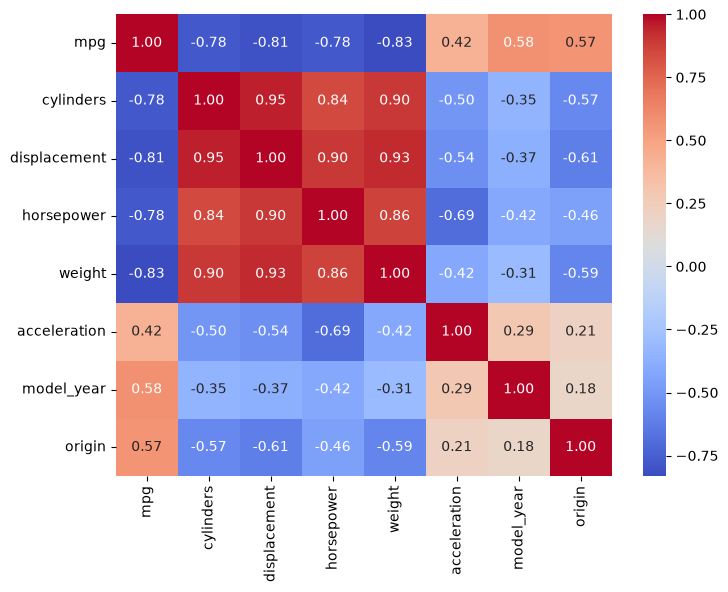

In [11]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show

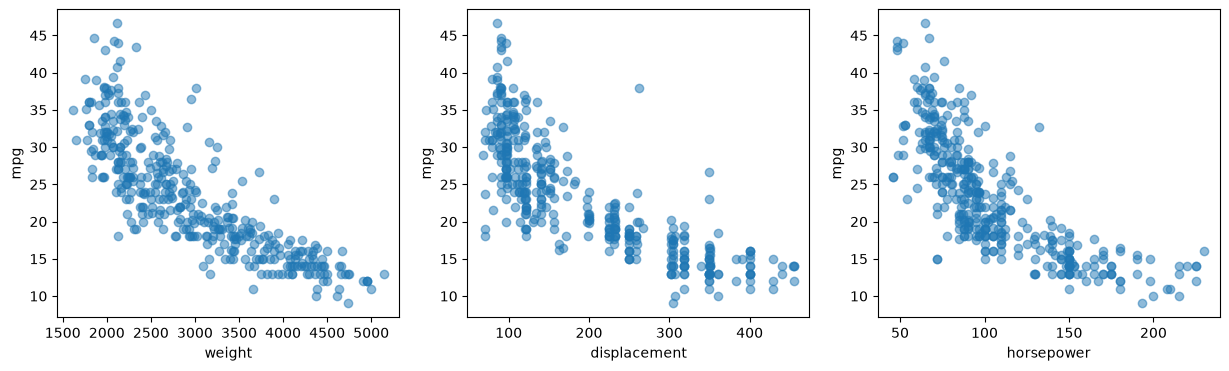

In [12]:
top3 = corr.abs().sort_values(ascending = False).head(3).index
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, col in zip(axes,top3):
    ax.scatter(X[col],y,alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel('mpg')
plt.show()

**Ответьте на вопросы:**
- Какие признаки имеют наибольшую корреляцию с целевой переменной `mpg`?
- Какие признаки наиболее коррелируют между собой?
- Какие закономерности можно заметить на графиках `mpg` от наиболее коррелирующих признаков?
- Какие признаки, на ваш взгляд, могут быть неинформативными или шумовыми?

##### **Ответы на вопросы:**
**<font color="black">
    1) top3 = weight,displacement,horsepower
    2) cylinders и displacement; displacement и horsepower; displacement и weight
    3) При малом весе, объёме и мощности mpg падает резко, а потом кривая выполаживается и точки прижимаются к 10–15 mpg. Больше всего это похоже на гиперболу. . Для displacement видны вертикальные «полоски», потому что значения объёма стандартные и повторяются.
    4) acceleration, origin, model_year

</font>**

## **3. Предобработка данных**

**Задание:**  
- Разделите `X` и `y` на обучающую и тестовую выборки: `train_test_split` с `test_size=0.2` и `random_state=42`.
- Используйте `StandardScaler` для стандартизации признаков (**будьте внимательны**, предобработать нужно и обучающие, и тестовые данные).


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Ответьте на вопросы:**
- Зачем нужна стандартизация признаков перед обучением линейной регрессии?
- Что произойдёт, если не масштабировать признаки?
- Почему у объекта `StandardScaler` метод `fit_transform` применяется только к обучающей выборке, а `transform` — к тестовой?

##### **Ответы на вопросы:**
<font color="black">
    1) Выравнивание масштабов: Линейная регрессия находит веса для каждого признака; Ускорение сходимости;<br>
    2) Медленное обучение, ошибка интерпретации весов, дисбаланс для регуляризации; <br>
    3) Предотвращение утчечки данных  Метод .fit() вычисляет среднее значение и стандартное отклоение выборки. Если вызвать его на тестовых данных или на всем датасете сразу, модель «узнает» информацию о распределении тестового множества до этапа тестирования.
    Имитация реальных условий: Тестовая выборка моделирует «новые, еще не виденные данные». В продакшене новые данные приходят поочередно, и у нас нет возможности посчитать по ним общее среднее. Модель должна обрабатывать их строго по правилам, которые она выучила на этапе обучения.

    
</font>

## **4. Обучение обычной линейной регрессии и оценка**

**Задание:**  
- Обучите модель `LinearRegression` на нормализованных обучающих данных (`X_train_scaled`, `y_train`).
- Сделайте предсказания на тестовой выборке: `y_pred_lr = model.predict(...)`.
- Рассчитайте `MSE` и `R²` с помощью `mean_squared_error` и `r2_score`.
- Постройте график: `y_test` по оси X, `y_pred_lr` по оси Y. Добавьте линию `y=x` (идеальная модель).



In [14]:
model = LinearRegression()
model.fit(X_train_scaled,y_train)

y_pred_lr = model.predict(X_test_scaled)

mse = mean_squared_error(y_test,y_pred_lr)
r2 = r2_score(y_test,y_pred_lr)
print(mse,r2)

10.710864418838394 0.7901500386760345


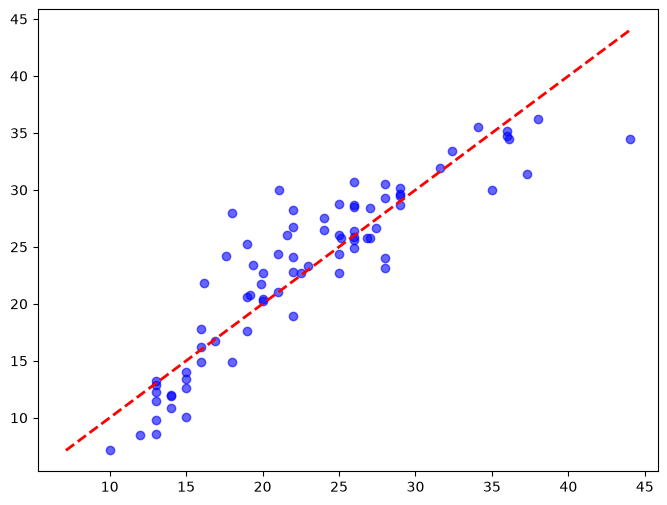

In [15]:
plt.figure(figsize=(8,6))
plt.scatter(y_test , y_pred_lr, color ="blue",alpha=0.6, label="Prediction")

min_val = min(y_test.min(), y_pred_lr.min())
max_val = max(y_test.max(), y_pred_lr.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Идеальная модель (y=x)",
)

- Как интерпретировать значение `R²`? Что означает `R² = 0` или `R² < 0`?
- Какова разница между `MSE` и `R²` как метриками качества?
- Что показывает график `y_test` vs `y_pred_lr`?

##### **Ответы на вопросы:**
**<font color="black">

1. Интерпретация: Коэффициент детерминации R² показывает долю дисперсии целевой переменной, которую объясняет модель. Если R² = 0.85, это значит, что модель объясняет 85% изменчивости данных.
R² = 0: Модель предсказывает константу — просто среднее значение целевой переменной по обучающей выборке. Она не уловила никаких зависимостей.
R² < 0: Модель работает хуже, чем простое предсказание среднего значения. Это сигнализирует о грубых ошибках (например, модель сильно переобучилась, перепутаны выборки или выбрана неподходящая архитектура).

2. 
MSE (Mean Squared Error): Абсолютная метрика. Она измеряется в квадратах единиц целевой переменной. Показывает средний квадрат ошибки, чувствительна к выбросам, но её трудно оценивать абстрактно (не зная масштаба данных, нельзя сказать, много ли значит mse=100).
R²: Относительная (нормализованная) метрика. Она безразмерна (обычно лежит в диапазоне от -inf До 1). Позволяет легко оценить качество модели независимо от масштаба целевого признака и сравнивать разные модели между собой.

3. Что показывает график y_test vs y_pred_lr?

• График наглядно демонстрирует точность и характер ошибок модели.
• Чем ближе точки к пунктирной диагональной линии y=x, тем качественнее модель.
• По графику можно заметить систематические отклонения: например, если при больших значениях y точки систематически уходят ниже линии, значит, модель занижает предсказания на высоких диапазонах.    
</font>**

## **5. Подбор степени полинома с кросс-валидацией**

>Ознакомьтесь с теоретической информации прежде чем перейти к решению задачи:

**Полиномиальная регрессия**

**1. Что такое полиномиальная регрессия?**

Полиномиальная регрессия — это расширение линейной регрессии, которое позволяет моделировать **нелинейные зависимости** между признаками и целевой переменной. В отличие от обычной линейной регрессии, которая строит модель вида:

$$
y = w_0 + w_1 x_1 + w_2 x_2 + \ldots + w_p x_p
$$

полиномиальная регрессия **добавляет в модель признаки, возведённые в степени** (например, $x^2$, $x^3$, $x_1 x_2$ и т.д.), что позволяет строить **кривые линии** или **поверхности**.

Пример модели 2-й степени:
$$
y = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_1^2 + w_4 x_2^2 + w_5 x_1 x_2
$$

Это всё ещё **линейная модель** по параметрам $w_i$, но **нелинейная** по входным признакам.

---

**2. Отличие от обычной линейной регрессии**

| Характеристика | Обычная линейная регрессия | Полиномиальная регрессия |
|----------------|----------------------------|---------------------------|
| Вид зависимости | Линейная (гиперплоскость) | Нелинейная (кривая, поверхность) |
| Возможность моделирования | Только линейные зависимости | Нелинейные зависимости |
| Количество признаков | Оригинальные признаки | Оригинальные + полиномиальные (степени, произведения) |
| Сложность модели | Простая, интерпретируемая | Более сложная, может быть переобучена |
| Подходит для | Простых линейных зависимостей | Задач с нелинейной структурой |

---

**3. Как собрать пайплайн для полиномиальной регрессии**

В `scikit-learn` удобно использовать `Pipeline` для последовательного применения трансформеров (генератора полиномиальных признаков и стандартизатора для предобработки данных) и модели. Это позволяет избежать ошибок (например, утечки данных) и упрощает код.

**Пример пайплайна:**

```python
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

poly_reg = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),  # Генерация полиномиальных признаков
    ('scaler', StandardScaler()),                               # Нормализация признаков
    ('lin_reg', LinearRegression())                             # Обычная линейная регрессия
])




**Кросс-валидация (Cross-Validation)**

**1. Что такое кросс-валидация?**

Кросс-валидация — это метод оценки **обобщающей способности** модели, при котором данные **разбиваются на несколько частей (фолдов)**. Модель обучается на **части** этих данных и тестируется на **оставшейся части**, и этот процесс повторяется **несколько раз**. Результаты усредняются, чтобы получить **более надёжную оценку качества**.

Наиболее популярный вид — **k-фолд кросс-валидация**, где данные делятся на `k` равных частей. Модель обучается на `k-1` частях и тестируется на оставшейся части. Это повторяется `k` раз, каждый раз с новой тестовой частью.

---

**2. Зачем нужна кросс-валидация?**

| Проблема | Решение с помощью кросс-валидации |
|----------|----------------------------------|
| Оценка качества на одном тестовом наборе может быть **нестабильной** | Кросс-валидация усредняет результаты по нескольким фолдам |
| Риск **переобучения** при подборе гиперпараметров | Модель оценивается на разных подмножествах данных |
| Утечка данных при неправильном использовании тестовой выборки | Кросс-валидация работает только с обучающими данными |
| Недостаток данных | Позволяет использовать **все данные** как для обучения, так и для тестирования (но не одновременно) |

---

**3. Как использовать `cross_val_score` в `scikit-learn`**

`cross_val_score` — это удобная функция, которая автоматически выполняет k-фолд кросс-валидацию и возвращает массив оценок (например, `R²`, `MSE` и т.д.).

**Важное замечание: стандартизация в пайплайне**

При использовании `cross_val_score` с `Pipeline`, **все трансформации** (включая `StandardScaler`) применяются **внутри каждого фолда**:

- На **обучающей части** фолда вычисляются параметры трансформера (например, среднее и стандартное отклонение для `StandardScaler`).
- Эти параметры **применяются** к **обучающей и тестовой части** фолда.

Это **предотвращает утечку данных**, так как параметры трансформации не зависят от всей выборки.

**Поэтому:**

- На вход `cross_val_score` (и, соответственно, в пайплайн) **нужно подавать исходные, необработанные данные** (например, `X_train`, а не `X_train_scaled`).
- **Предварительная нормализация** всех данных перед кросс-валидацией **недопустима**, так как приведёт к утечке данных и **завышенной оценке качества**.

**Пример использования:**

```python
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Создаём пайплайн
model = Pipeline([
    ('scaler', StandardScaler()),
    ('reg', LinearRegression())
])

# Применяем кросс-валидацию (5 фолдов, метрика R²)
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')

print("Оценки по фолдам:", scores)
print("Средняя оценка (R²):", scores.mean())
print("Стандартное отклонение:", scores.std())



**Задание:**  
Для степеней `degree = [1, 2, 3, 4, 5]`:
- Используйте `Pipeline` с `PolynomialFeatures`, `StandardScaler` и `LinearRegression`.
- Оцените модель с помощью `cross_val_score` (5 фолдов, `scoring='r2'`).
- Выведите полученное значение `R²` для каждой степени.
- Сохраните результаты в список или `DataFrame` и определите лучшую степень (с наибольшим средним `R²`).
- Постройте график (по одной оси - значение `R²`, по другой - соответствующая степень из `degree`).

Степень (degree) = 1: Средний R2 = 0.5946
Степень (degree) = 2: Средний R2 = 0.6790
Степень (degree) = 3: Средний R2 = -0.1062
Степень (degree) = 4: Средний R2 = -84.4737
Степень (degree) = 5: Средний R2 = -89.0638

Лучшая степень: 2 со средним R2 = 0.6790


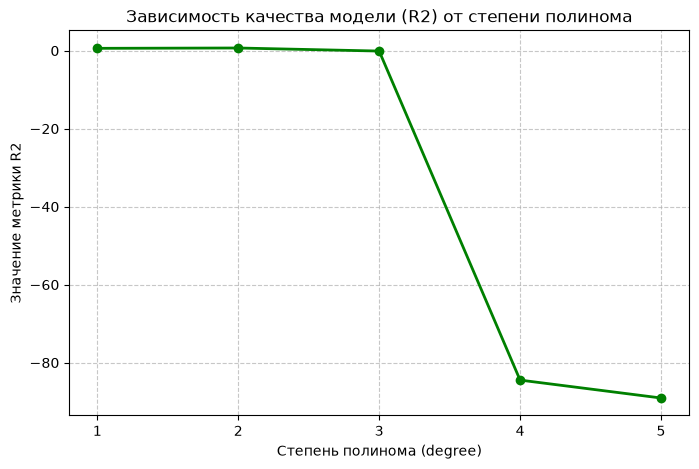

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

degrees = [1, 2, 3, 4, 5]
mean_r2_scores = []

for degree in degrees:
    # 1. Создание Pipeline: полиномиальные признаки -> стандартизация -> линейная регрессия
    pipeline = Pipeline(
        [
            ("polynomial_features", PolynomialFeatures(degree=degree)),
            ("scaler", StandardScaler()),
            ("linear_regression", LinearRegression()),
        ]
    )

    # 2. Оценка модели с помощью кросс-валидации (5 фолдов, метрика R2)
    scores = cross_val_score(pipeline, X, y, cv=5, scoring="r2")

    mean_score = np.mean(scores)
    mean_r2_scores.append(mean_score)

    # 3. Вывод полученного значения R² для текущей степени
    print(f"Степень (degree) = {degree}: Средний R2 = {mean_score:.4f}")

# 4. Сохранение результатов в DataFrame и определение лучшей степени
results_df = pd.DataFrame({"Degree": degrees, "Mean_R2": mean_r2_scores})

best_row = results_df.loc[results_df["Mean_R2"].idxmax()]
print(
    f"\nЛучшая степень: {int(best_row['Degree'])} со средним R2 = {best_row['Mean_R2']:.4f}"
)

plt.figure(figsize=(8, 5))
plt.plot(degrees, mean_r2_scores, marker="o", color="green", linewidth=2)
plt.xlabel("Степень полинома (degree)")
plt.ylabel("Значение метрики R2")
plt.title("Зависимость качества модели (R2) от степени полинома")
plt.xticks(degrees)
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

**Ответьте на вопросы:**
- Какая степень полинома дала наилучший результат? Почему более высокие степени могут ухудшить качество?
- Почему кросс-валидация способна дать более достоверную оценку модели в сравнении с однократным разделением обучающих данных на train и val, обучением на train и оценкой на val?

##### **Ответы на вопросы:**
<font color="black">
 Какая степень лучшая: 2
 Почему высокие степени ухудшают качество: С увеличением степени полинома модель становится избыточно сложной. Она начинает подстраиваться под случайные шумы и выбросы в обучающей выборке вместо поиска реальной закономерности. Это приводит к переобучению (overfitting): на тренировочных данных ошибка падает до нуля, но на новых (тестовых или валидационных) данных качество резко ухудшается, а коэффициенты модели становятся огромными.
<br>
 Исключение случайности: При однократном разделении (train_test_split) в валидационную выборку могут случайно попасть либо слишком простые, либо аномально сложные примеры. Оценка будет искажена. Кросс-валидация проверяет модель на разных подмножествах данных, нивелируя этот случайный фактор.
 Использование всех данных: Каждый объект выборки успевает побывать и в роли обучающего примера, и в роли валидационного. Это даёт максимально полную картину того, как модель обобщает информацию.
 Оценка стабильности: Кросс-валидация позволяет посчитать не просто одно число, а среднее значение и стандартное отклонение метрики. Это помогает понять, насколько устойчиво работает алгоритм при изменении входных данных.
    </font>

## **6. Обучение финальной модели на лучшей степени**

**Задание:**  
- Соберите финальный `Pipeline` с лучшей степенью полинома.
- Обучите модель на всей обучающей выборке (`X_train`, `y_train`).
- Сделайте предсказания на тестовой выборке и рассчитайте `MSE` и `R²`.
- Сравните качество (`R²`) финальной модели с линейной регрессией из п. 4.
- Постройте тот же график, что и в п. 4, но для финальной модели.

Линейная регрессия (п.4):  MSE = 10.711, R² = 0.7902
Полином степени 2:      MSE = 7.157, R² = 0.8598


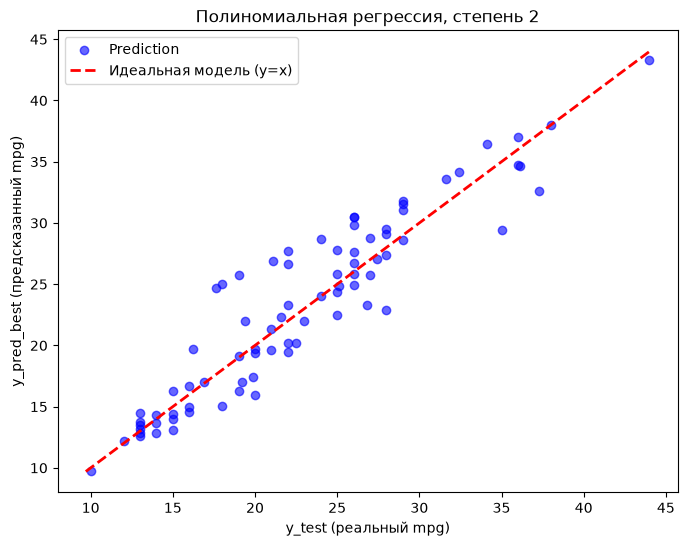

In [17]:
best_degree = int(best_row['Degree'])

final_model = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=best_degree)),
    ("scaler", StandardScaler()),
    ("linear_regression", LinearRegression()),
])

final_model.fit(X_train, y_train)



y_pred_best = final_model.predict(X_test)

mse_best = mean_squared_error(y_test, y_pred_best)
r2_best = r2_score(y_test, y_pred_best)

print(f"Линейная регрессия (п.4):  MSE = {mse:.3f}, R² = {r2:.4f}")
print(f"Полином степени {best_degree}:      MSE = {mse_best:.3f}, R² = {r2_best:.4f}")




plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, color="blue", alpha=0.6, label="Prediction")

min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linestyle="--", linewidth=2, label="Идеальная модель (y=x)")

plt.xlabel("y_test (реальный mpg)")
plt.ylabel("y_pred_best (предсказанный mpg)")
plt.title(f"Полиномиальная регрессия, степень {best_degree}")
plt.legend()
plt.show()

- Удалось ли улучшить качество модели по сравнению с линейной регрессией? Какие метрики изменились?
- Что показывает график `y_test` vs `y_pred_best` для финальной модели? Стало ли приближение лучше?
- Как бы вы интерпретировали результаты в контексте исходной задачи (предсказание расхода топлива)?

##### **Ответы на вопросы:**
<font color="black">
    Качество улучшилось: R² выросло (было - 0.7902, стало - 0.8598), а MSE упал (было - 10.711, стало - 7.157). <br>
    Чем ближе точки к красной линии y=x, тем точнее предсказания. Приближение стало лучше. У линейной модели пропал систематический перекос на краях. <br>
Насколько в милях на галлон ошибается модель (корень из MSE) = ~2.65
 достаточно ли этого на практике и почему нелинейность оправдана (расход не падает линейно с весом и мощностью).
    
</font>